# Assignment 10 — Command-Line To-Do Manager Agent

**Objective:** Develop a command-line to-do manager agent that maintains simple state.

The agent stores tasks in memory and allows the user to add, remove, complete, and view tasks. The task list is the agent's current state.

## Features

- Add a new task
- View all tasks
- Mark a task as completed
- Remove a task
- Clear all tasks
- Show task statistics
- Interactive command-line menu

The program maintains the same task state throughout the session.

In [1]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

## Step 1 — Create the To-Do Agent

The agent uses a list of dictionaries to store each task. Each task has a name and a completed status.

In [2]:
class TodoAgent:
    def __init__(self):
        # This list is the current state of the agent
        self.tasks = []

    def add_task(self, task_name):
        task_name = task_name.strip()

        if task_name == "":
            return "Task cannot be empty."

        self.tasks.append({
            "task": task_name,
            "completed": False
        })

        return "Task added successfully."

    def view_tasks(self):
        if not self.tasks:
            return "No tasks available."

        result = []

        for i, item in enumerate(self.tasks, start=1):
            status = "✓" if item["completed"] else " "
            result.append(f"{i}. [{status}] {item['task']}")

        return "\n".join(result)

    def complete_task(self, task_number):
        if task_number < 1 or task_number > len(self.tasks):
            return "Invalid task number."

        self.tasks[task_number - 1]["completed"] = True
        return "Task marked as completed."

    def remove_task(self, task_number):
        if task_number < 1 or task_number > len(self.tasks):
            return "Invalid task number."

        removed = self.tasks.pop(task_number - 1)
        return f"Removed: {removed['task']}"

    def clear_tasks(self):
        self.tasks.clear()
        return "All tasks cleared."

    def get_stats(self):
        total = len(self.tasks)
        completed = sum(1 for task in self.tasks if task["completed"])
        pending = total - completed

        return total, completed, pending

## Step 2 — Test the agent

Before using the interactive menu, we can test the main operations directly.

In [3]:
todo = TodoAgent()

print(todo.add_task("Complete AI assignment"))
print(todo.add_task("Study for exam"))
print(todo.add_task("Go to the gym"))

print("\nCurrent tasks:")
print(todo.view_tasks())

print("\n" + todo.complete_task(1))

print("\nUpdated tasks:")
print(todo.view_tasks())

Task added successfully.
Task added successfully.
Task added successfully.

Current tasks:
1. [ ] Complete AI assignment
2. [ ] Study for exam
3. [ ] Go to the gym

Task marked as completed.

Updated tasks:
1. [✓] Complete AI assignment
2. [ ] Study for exam
3. [ ] Go to the gym


## Step 3 — Display task statistics

In [4]:
total, completed, pending = todo.get_stats()

print("Task Statistics")
print("---------------")
print("Total tasks:", total)
print("Completed:", completed)
print("Pending:", pending)

Task Statistics
---------------
Total tasks: 3
Completed: 1
Pending: 2


## Step 4 — Visualize task status

The chart gives a quick view of completed versus pending tasks.

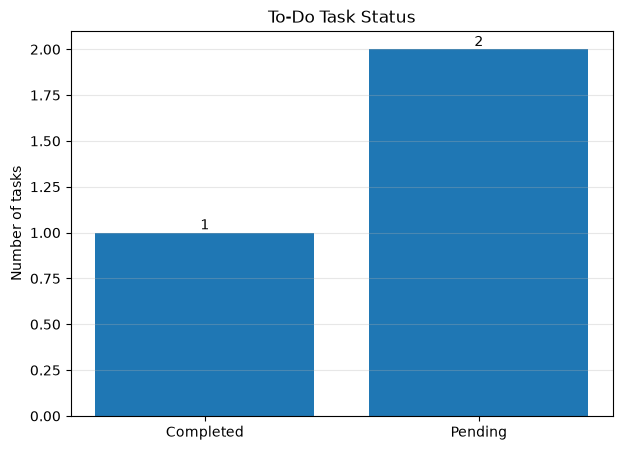

In [5]:
def show_statistics(agent):
    total, completed, pending = agent.get_stats()

    labels = ["Completed", "Pending"]
    values = [completed, pending]

    plt.figure(figsize=(7, 5))
    bars = plt.bar(labels, values)

    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            str(value),
            ha="center",
            va="bottom"
        )

    plt.title("To-Do Task Status")
    plt.ylabel("Number of tasks")
    plt.grid(axis="y", alpha=0.3)
    plt.show()


show_statistics(todo)

## Step 5 — Show the agent's current state

The task list is the internal state maintained by the agent.

In [6]:
def show_current_state(agent):
    clear_output(wait=True)

    print("TO-DO AGENT")
    print("=" * 45)

    if not agent.tasks:
        print("No tasks available.")
    else:
        for i, item in enumerate(agent.tasks, start=1):
            status = "DONE" if item["completed"] else "PENDING"
            print(f"{i}. [{status}] {item['task']}")

    total, completed, pending = agent.get_stats()
    print("\nTotal:", total, "| Completed:", completed, "| Pending:", pending)

## Step 6 — Interactive command-line manager

Use the menu to manage tasks. The state remains available until the program is exited.

In [7]:
def run_todo_agent():
    agent = TodoAgent()

    while True:
        print("\n" + "=" * 40)
        print("       TO-DO MANAGER AGENT")
        print("=" * 40)
        print("1. Add task")
        print("2. View tasks")
        print("3. Complete task")
        print("4. Remove task")
        print("5. Clear all tasks")
        print("6. Show statistics")
        print("7. Exit")

        choice = input("Enter your choice: ").strip()

        if choice == "1":
            task = input("Enter task: ")
            print(agent.add_task(task))

        elif choice == "2":
            print("\n" + agent.view_tasks())

        elif choice == "3":
            try:
                number = int(input("Enter task number: "))
                print(agent.complete_task(number))
            except ValueError:
                print("Please enter a valid number.")

        elif choice == "4":
            try:
                number = int(input("Enter task number: "))
                print(agent.remove_task(number))
            except ValueError:
                print("Please enter a valid number.")

        elif choice == "5":
            print(agent.clear_tasks())

        elif choice == "6":
            total, completed, pending = agent.get_stats()
            print("\nTotal tasks:", total)
            print("Completed:", completed)
            print("Pending:", pending)

        elif choice == "7":
            print("To-do manager closed.")
            break

        else:
            print("Invalid choice. Please try again.")


run_todo_agent()


       TO-DO MANAGER AGENT
1. Add task
2. View tasks
3. Complete task
4. Remove task
5. Clear all tasks
6. Show statistics
7. Exit
Invalid choice. Please try again.

       TO-DO MANAGER AGENT
1. Add task
2. View tasks
3. Complete task
4. Remove task
5. Clear all tasks
6. Show statistics
7. Exit
Invalid choice. Please try again.

       TO-DO MANAGER AGENT
1. Add task
2. View tasks
3. Complete task
4. Remove task
5. Clear all tasks
6. Show statistics
7. Exit
Task added successfully.

       TO-DO MANAGER AGENT
1. Add task
2. View tasks
3. Complete task
4. Remove task
5. Clear all tasks
6. Show statistics
7. Exit

1. [ ] go to gym

       TO-DO MANAGER AGENT
1. Add task
2. View tasks
3. Complete task
4. Remove task
5. Clear all tasks
6. Show statistics
7. Exit
To-do manager closed.


## Step 7 — State-change simulation

This simulation shows how the agent's state changes as tasks are added and completed.

In [8]:
agent = TodoAgent()

operations = [
    ("Add", "Complete project report"),
    ("Add", "Submit assignment"),
    ("Add", "Prepare presentation")
]

state_history = []

for operation, task in operations:
    agent.add_task(task)
    total, completed, pending = agent.get_stats()
    state_history.append((total, completed, pending))

agent.complete_task(1)
total, completed, pending = agent.get_stats()
state_history.append((total, completed, pending))

print("State history:")
for i, state in enumerate(state_history, start=1):
    print(f"Step {i}: Total={state[0]}, Completed={state[1]}, Pending={state[2]}")

State history:
Step 1: Total=1, Completed=0, Pending=1
Step 2: Total=2, Completed=0, Pending=2
Step 3: Total=3, Completed=0, Pending=3
Step 4: Total=3, Completed=1, Pending=2


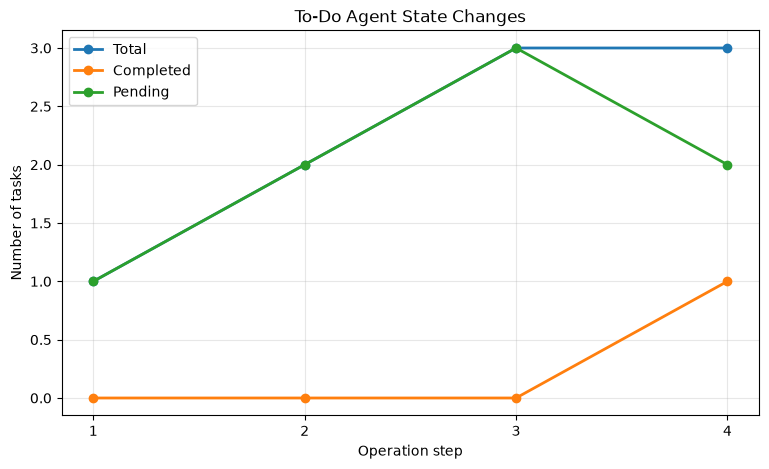

In [9]:
steps = list(range(1, len(state_history) + 1))
total_values = [state[0] for state in state_history]
completed_values = [state[1] for state in state_history]
pending_values = [state[2] for state in state_history]

plt.figure(figsize=(9, 5))
plt.plot(steps, total_values, marker="o", linewidth=2, label="Total")
plt.plot(steps, completed_values, marker="o", linewidth=2, label="Completed")
plt.plot(steps, pending_values, marker="o", linewidth=2, label="Pending")
plt.xlabel("Operation step")
plt.ylabel("Number of tasks")
plt.title("To-Do Agent State Changes")
plt.xticks(steps)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Final result

The to-do agent maintains a simple internal state throughout the session. Changes made through one command are available to later commands.

In [10]:
final_agent = TodoAgent()
final_agent.add_task("Finish assignment")
final_agent.add_task("Submit notebook")
final_agent.complete_task(1)

total, completed, pending = final_agent.get_stats()

print("To-Do Manager Agent")
print("-------------------")
print(final_agent.view_tasks())
print("\nTotal:", total)
print("Completed:", completed)
print("Pending:", pending)

To-Do Manager Agent
-------------------
1. [✓] Finish assignment
2. [ ] Submit notebook

Total: 2
Completed: 1
Pending: 1
